In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import numpy as np
import random
import pandas as pd


In [ ]:
#get helper functions
%run '/content/drive/MyDrive/Colab Notebooks/RCC_Beam_Optimization/helper_functions.ipynb'


In [ ]:
param_ranges

{'b': (200.0, 500.0), 'd': (300.0, 1500.0), 'Ast': (200.0, 10000.0)}

In [ ]:
width_bins = np.arange(param_ranges['b'][0],param_ranges['b'][1]+1,10)  # mm
depth_bins = np.arange(param_ranges['d'][0],param_ranges['d'][1]+1,10)  # mm
ast_bins = np.arange(param_ranges['Ast'][0],param_ranges['Ast'][1]+1,10)  # mm²

In [ ]:
def get_optimal_designs_brute_force(fck, fy, Mu, threshold=0):
  designs = []
  for b_idx in range(len(width_bins)):
      for d_idx in range(len(depth_bins)):
          for a_idx in range(len(ast_bins)):
              b = width_bins[b_idx]
              d = depth_bins[d_idx]
              Ast = ast_bins[a_idx]

              if is_valid_design(b, d, Ast, fck, fy, Mu):
                  reward = get_reward(b, d, Ast, fck, fy, Mu)
                  if reward > threshold:
                      designs.append((b, d, Ast, reward))
  return sorted(designs, key=lambda x: x[3], reverse=True)

In [ ]:
# Show top 5 designs with utilization ratio

optimal = get_optimal_designs_brute_force(fck, fy, applied_moment)

print("Top optimal designs:", len(optimal))
for design in optimal[:5]:
    b, d, Ast, reward = design
    cost = get_cost(b, d, Ast)
    MOR, Mul = calculate_moment_capacity(b, d, Ast, fck, fy)
    utilization = applied_moment / MOR if MOR != 0 else 0  # Prevent divide-by-zero
    print(f"Width: {b}mm, Depth: {d}mm, Ast: {Ast}mm²")
    print(f"Reward: {reward:.2f}, Cost: {cost}, Mu/MoR: {utilization:.2f}, MoR: {MOR:.2f}, Mul: {Mul:.2f}")
    print("-"*100)


Top optimal designs: 142920
Width: 360.0mm, Depth: 1200.0mm, Ast: 5650.0mm²
Reward: 9.39, Cost: 12689.35, Mu/MoR: 1.00, MoR: 2002.67, Mul: 2147.77
----------------------------------------------------------------------------------------------------
Width: 360.0mm, Depth: 1200.0mm, Ast: 5660.0mm²
Reward: 9.37, Cost: 12700.34, Mu/MoR: 1.00, MoR: 2005.43, Mul: 2147.77
----------------------------------------------------------------------------------------------------
Width: 360.0mm, Depth: 1200.0mm, Ast: 5670.0mm²
Reward: 9.36, Cost: 12711.33, Mu/MoR: 1.00, MoR: 2008.18, Mul: 2147.77
----------------------------------------------------------------------------------------------------
Width: 360.0mm, Depth: 1190.0mm, Ast: 5720.0mm²
Reward: 9.36, Cost: 12712.28, Mu/MoR: 1.00, MoR: 2001.25, Mul: 2112.12
----------------------------------------------------------------------------------------------------
Width: 360.0mm, Depth: 1200.0mm, Ast: 5680.0mm²
Reward: 9.34, Cost: 12722.32, Mu/MoR: 0.99, 

In [ ]:
is_valid_design(360, 1200, 4690, 30, 500, 2000)

True

In [ ]:
get_cost(360, 1200, 4690)

11634.31

##Comparison

In [ ]:

# Load dataset
df_all = pd.read_csv("ensemble_best_designs_1029.csv")

# Randomly pick 10 settings
sampled_settings = df_all[["fck", "fy", "Mu"]].drop_duplicates().sample(n=10, random_state=42)
sampled_settings.head()

,fck,fy,Mu
290,25,550,940
534,35,500,920
261,25,550,360
107,20,550,220
425,30,550,700


In [ ]:
comparison_rows = []

for _, row in sampled_settings.iterrows():
    fck, fy, Mu = row["fck"], row["fy"], row["Mu"]

    # Get ensemble-selected design
    ensemble_row = df_all[(df_all.fck == fck) & (df_all.fy == fy) & (df_all.Mu == Mu)].iloc[0]
    cost_ensemble = get_cost(ensemble_row.b, ensemble_row.d, ensemble_row.Ast)

    # Get best brute-force design
    best_brute = get_optimal_designs_brute_force(fck, fy, Mu, threshold=0)
    if best_brute:
        b_bf, d_bf, Ast_bf, reward_bf = best_brute[0]
        cost_bf = get_cost(b_bf, d_bf, Ast_bf)
    else:
        cost_bf = None

    comparison_rows.append({
        "fck": fck,
        "fy": fy,
        "Mu": Mu,
        "cost_ensemble": round(cost_ensemble, 2),
        "cost_brute": round(cost_bf, 2) if cost_bf else None,
        "better_method": "Ensemble" if cost_bf and cost_ensemble < cost_bf else "Brute Force" if cost_bf else "Ensemble (No BF)"
    })


In [ ]:
df_cmp = pd.DataFrame(comparison_rows)
df_cmp.head()

,fck,fy,Mu,cost_ensemble,cost_brute,better_method
0,25,550,940,7080.73,7125.57,Ensemble
1,35,500,920,6721.08,6744.18,Ensemble
2,25,550,360,3743.20,3771.70,Ensemble
3,20,550,220,2913.24,2914.15,Ensemble
4,30,550,700,5535.99,5606.95,Ensemble


In [ ]:
df_cmp.to_csv("comparison_results.csv", index=False)

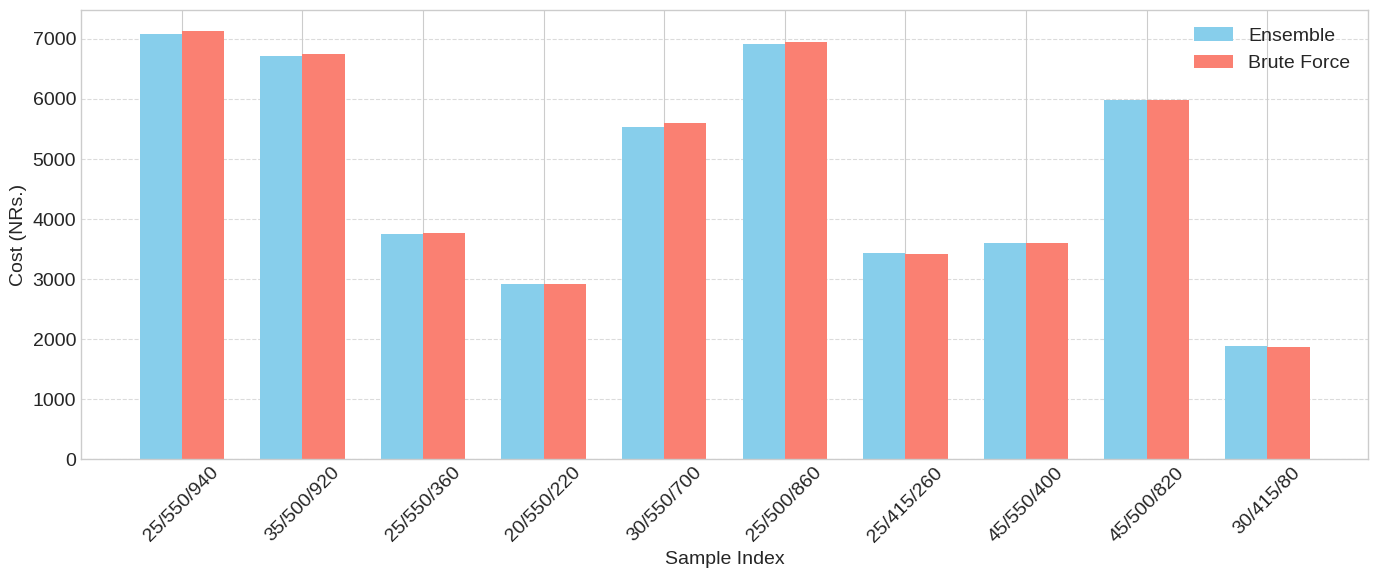

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid') # Uses the classic seaborn whitegrid profile natively
plt.rcParams.update({'font.size': 14})  # Manually inject your custom text size

plt.figure(figsize=(14, 6))
x = np.arange(len(df_cmp))
width = 0.35

plt.bar(x - width/2, df_cmp["cost_ensemble"], width, label='Ensemble', color='skyblue')
plt.bar(x + width/2, df_cmp["cost_brute"], width, label='Brute Force', color='salmon')

plt.xlabel("Sample Index")
plt.ylabel("Cost (NRs.)")
# plt.title("Cost Comparison: Ensemble vs Brute Force")
plt.xticks(x, labels=[f"{int(row.fck)}/{int(row.fy)}/{int(row.Mu)}" for _, row in df_cmp.iterrows()], rotation=45)
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig("comparison.png", dpi=300, bbox_inches="tight")
plt.show()


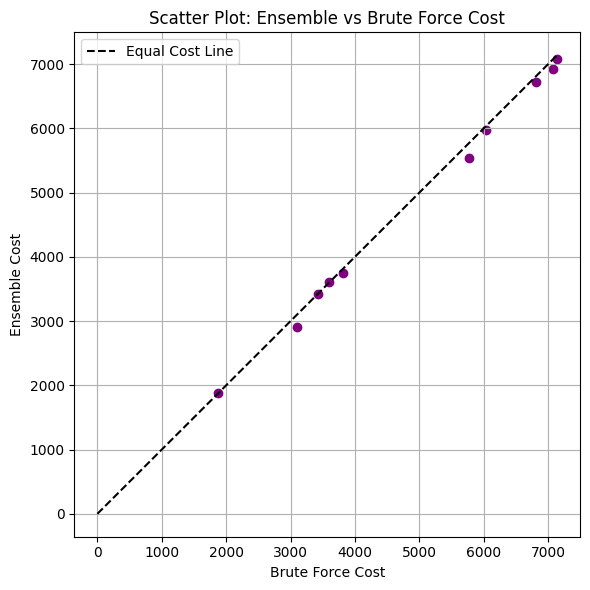

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(df_cmp["cost_brute"], df_cmp["cost_ensemble"], color='purple')

max_cost = max(df_cmp["cost_brute"].max(), df_cmp["cost_ensemble"].max())
plt.plot([0, max_cost], [0, max_cost], 'k--', label="Equal Cost Line")

plt.xlabel("Brute Force Cost")
plt.ylabel("Ensemble Cost")
plt.title("Scatter Plot: Ensemble vs Brute Force Cost")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

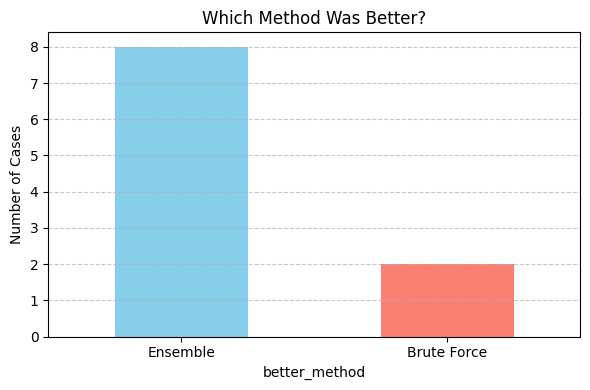

In [ ]:
win_counts = df_cmp["better_method"].value_counts()

plt.figure(figsize=(6, 4))
win_counts.plot(kind='bar', color=["skyblue", "salmon", "gray"])
plt.ylabel("Number of Cases")
plt.title("Which Method Was Better?")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


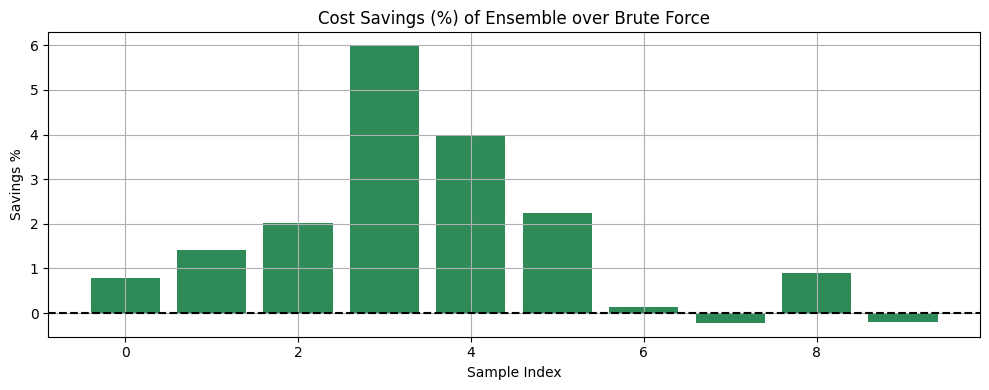

In [ ]:
df_cmp["savings_percent"] = 100 * (df_cmp["cost_brute"] - df_cmp["cost_ensemble"]) / df_cmp["cost_brute"]
plt.figure(figsize=(10, 4))
plt.bar(range(len(df_cmp)), df_cmp["savings_percent"], color="seagreen")
plt.axhline(0, color='black', linestyle='--')
plt.title("Cost Savings (%) of Ensemble over Brute Force")
plt.ylabel("Savings %")
plt.xlabel("Sample Index")
plt.grid(True)
plt.tight_layout()
plt.show()


#New data generation

In [ ]:
# Define new input ranges beyond original data
fck_values = [20, 25, 30]           # Example range or extrapolated values
fy_values = [500, 550]                      # Could add higher grades
Mu_values = [550, 580, 600, 650]       # Higher than previously seen

# Store results
designs = []

# Generate new designs
for fck in fck_values:
    for fy in fy_values:
        for Mu in Mu_values:
            b, d, Ast, reward = get_optimal_designs_brute_force(fck, fy, Mu)[0]
            validity = is_valid_design(b, d, Ast, fck, fy, Mu)
            cost = get_cost(b, d, Ast)
            designs.append({'fck': fck, 'fy': fy, 'Mu': Mu, 'b': b, 'd':d, 'Ast':Ast, 'is_valid': validity, 'cost': cost})

# Convert to DataFrame
df_new = pd.DataFrame(designs)


df_new.to_csv("generated_data.csv", index=False)

df_new.head()

,fck,fy,Mu,b,d,Ast,is_valid,cost
0,20,500,550,275.0,875.0,1775.0,True,5560.10
1,20,500,580,275.0,900.0,1825.0,True,5718.18
2,20,500,600,300.0,875.0,1950.0,True,6080.55
3,20,500,650,325.0,875.0,2100.0,True,6573.52
4,20,550,550,275.0,900.0,1550.0,True,5415.95
